# Q1: redundant base-phi digits vs signed binary under one block-sparsity optimiser

**Question.** A weight is `s * sum_k d_k * b^k` with digits `d_k in {-1, 0, 1}` over `K` planes.
Base `phi = (1+sqrt5)/2` is redundant (`phi^2 = phi + 1`), so most values have many digit strings.
Signed binary is redundant too (`2^(k+1) - 2^k = 2^k`, the CSD / NAF freedom). Bit-serial accelerators
skip a `(block, plane)` pair when every digit in the block is zero on that plane, so the useful
question is: at **matched quantisation MSE**, and with the **same block optimiser** applied to both,
does phi give fewer active block-ops than binary?

**Method.**
1. Enumerate all `3^K` digit strings with exact integer arithmetic (`phi^k = F_k*phi + F_(k-1)`), group by
   exact value: each group is an equivalence class (the redundancy). Keep the antichain of minimal
   nonzero-plane masks per class (a mask that strictly contains another can never help).
2. Quantise Gaussian and Laplacian `N x N` matrices (N = 256, 512, seeds 0..2) with a grid-searched global scale
   `s` for every `(base, K)`; also plain INT-k symmetric grids as a distortion-only reference.
3. For block shapes 1x4, 1x8, 2x2, 4x4 (8x8 diagnostic, seed 0 only), choose one digit string per entry to
   minimise `popcount(OR of masks)` per block. Heuristic = greedy plane elimination with several fixed and
   random elimination orders (local search), run on **all** blocks. Exact reference on a 200-block sample per
   configuration via a subset-closure DP over all `2^K` plane sets, plus a CP-SAT / CBC ILP cross-check on
   a subset of configurations when a solver is installed. The **identical** optimiser runs on binary; the
   unoptimised baseline is the minimal-weight canonical string per entry with no block coordination.
4. Metrics: MSE, nonzero digits, active block-ops (`sum over planes and blocks of rows*cols if active`),
   per-plane active fraction, raw storage bits `N*N*K*log2(3)`.

Outputs: `figs/q1_fig*.png`, `results/q1_*.csv`, `results/q1_planes.npz`, `results/q1_decision.md`.
Everything is seeded; numpy only, plus `ortools` / `pulp` if importable.


In [1]:
from __future__ import annotations
import csv, math, os, sys, time
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

T_START = time.time()
def elapsed() -> str:
    return f'{time.time() - T_START:7.1f}s'

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIGS = ROOT / 'figs'
RES = ROOT / 'results'
FIGS.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

GLOBAL_SEED = 2026
PHI = (1.0 + 5.0 ** 0.5) / 2.0
K_RANGE = {'phi': list(range(4, 13)), 'bin': list(range(2, 9))}
INT_BITS = list(range(2, 9))
SIZES = [256, 512]
SEEDS = [0, 1, 2]
DISTS = ['gauss', 'laplace']
BLOCK_SHAPES = [(1, 4), (1, 8), (2, 2), (4, 4)]
DIAG_SHAPES = [(8, 8)]              # diagnostic only (seed 0), excluded from the decision
N_SAMPLE_BLOCKS = 200               # exact-solver validation sample per configuration
MAX_SLOTS = 32                      # candidate cap per entry inside the heuristic (exact solvers use all)
N_RANDOM_ORDERS = 3                 # random plane-elimination orders (local search restarts)
SUBSAMPLE = 32768                   # weights used for the scale grid search (final MSE uses all)
REF_MATRIX = ('gauss', 512, 0)      # matrix used for the plots and the saved planes
REF_BIN_K = 6                       # binary K of the matched-MSE pair
ILP_MATRICES = {('gauss', 256, 0)}  # where the ILP cross-check runs
ILP_SHAPES = [(1, 4), (4, 4)]
DECISION_SHAPES = [(1, 4), (4, 4)]
GO_THRESHOLD = 0.9
LABEL = {'phi': 'base phi', 'bin': 'signed binary'}

ILP_BACKEND = None
try:
    from ortools.sat.python import cp_model
    ILP_BACKEND = 'cpsat'
except Exception:
    try:
        import pulp
        ILP_BACKEND = 'cbc'
    except Exception:
        ILP_BACKEND = None

# chart chrome (dataviz palette: phi = slot 1 blue, binary = slot 2 orange, reference = muted ink)
C_PHI, C_BIN, C_INT = '#2a78d6', '#eb6834', '#898781'
COLORS = {'phi': C_PHI, 'bin': C_BIN}
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'xtick.color': '#898781', 'ytick.color': '#898781',
    'text.color': '#0b0b0b', 'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.8, 'grid.linestyle': '-',
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2.0, 'lines.markersize': 6,
    'legend.frameon': False, 'font.size': 10, 'figure.dpi': 100, 'savefig.dpi': 160, 'axes.axisbelow': True,
})
print(f'python {sys.version.split()[0]} | numpy {np.__version__} | ILP backend: {ILP_BACKEND} | cpus: {os.cpu_count()}')


python 3.12.0 | numpy 1.26.4 | ILP backend: None | cpus: 11


## 1. Exact enumeration of digit strings and equivalence classes

For phi, `phi^k = F_k * phi + F_(k-1)` with `F_-1 = 1, F_0 = 0, F_1 = 1`, so every digit string maps to an exact
integer pair `(a, b)` with value `a*phi + b`; strings are equivalent iff the pairs agree (phi is irrational).
For binary the string maps to one integer. Values are normalised so the top plane has weight 1
(lower planes are fractional positions relative to it); the global scale `s` absorbs the rest.


In [2]:
def popcount_table(bits: int) -> np.ndarray:
    return np.array([bin(i).count('1') for i in range(1 << bits)], dtype=np.int8)

POP16 = popcount_table(16)   # popcount for any mask below 2^16 (K <= 12 here)

def popcount32(x: np.ndarray) -> np.ndarray:
    # popcount for int64 arrays with values below 2^32 (slot bitmasks)
    return POP16[x & 0xFFFF].astype(np.int64) + POP16[(x >> 16) & 0xFFFF]

def fib_columns(K: int) -> tuple[np.ndarray, np.ndarray]:
    # (F_k, F_{k-1}) for k = 0..K-1 with F_-1 = 1, F_0 = 0, F_1 = 1
    F = [1, 0, 1]
    while len(F) < K + 2:
        F.append(F[-1] + F[-2])
    return np.array(F[1:K + 1], dtype=np.int64), np.array(F[0:K], dtype=np.int64)

def all_digit_strings(K: int) -> np.ndarray:
    n = 3 ** K
    idx = np.arange(n, dtype=np.int64)
    D = np.empty((n, K), dtype=np.int8)
    for k in range(K):
        D[:, k] = (idx // 3 ** k) % 3 - 1
    return D

def antichain(masks: np.ndarray) -> np.ndarray:
    # keep the masks that do not strictly contain another mask of the set (sorted ascending)
    m = np.unique(masks)
    if m.size <= 1:
        return m
    subset = (m[:, None] & ~m[None, :]) == 0      # subset[i, j]: m[i] is a subset of m[j]
    np.fill_diagonal(subset, False)
    return m[~subset.any(axis=0)]

@dataclass
class ClassTable:
    base: str
    K: int
    values: np.ndarray        # [n_cls] float, ascending, top plane weight = 1
    sizes: np.ndarray         # [n_cls] digit strings per class (the redundancy)
    n_masks: np.ndarray       # [n_cls] distinct nonzero-plane masks per class
    n_min: np.ndarray         # [n_cls] antichain (minimal) masks per class
    cand_lists: list          # [n_cls] int64 arrays of minimal masks sorted by (popcount, mask)
    cand: np.ndarray          # [n_cls, MAX_SLOTS] int64 masks, zero padded
    valid: np.ndarray         # [n_cls, MAX_SLOTS] bool
    slot_bits: np.ndarray     # [n_cls] int64 bitmask of the valid slots
    U: np.ndarray             # [n_cls, K] int64: slot bitmask of candidates that use plane p
    canon: np.ndarray         # [n_cls] int64 minimal-weight canonical mask (slot 0)
    digits: np.ndarray        # [n_cls, MAX_SLOTS, K] int8 representative digit string per slot
    truncated: int            # classes with more than MAX_SLOTS minimal masks

def build_class_table(base: str, K: int) -> ClassTable:
    D = all_digit_strings(K)
    Dl = D.astype(np.int64)
    powers = 1 << np.arange(K, dtype=np.int64)
    if base == 'phi':
        Fk, Fkm1 = fib_columns(K)
        a = Dl @ Fk
        b = Dl @ Fkm1
        key = (a + (1 << 20)) * (1 << 21) + (b + (1 << 20))     # exact (a, b) key; |a|, |b| < 2^20
        value = (a * PHI + b) / PHI ** (K - 1)
    else:
        a = Dl @ powers
        key = a
        value = a / 2.0 ** (K - 1)
    _, first, inv, counts = np.unique(key, return_index=True, return_inverse=True, return_counts=True)
    cls_value = value[first]
    order = np.argsort(cls_value, kind='stable')
    rank = np.empty_like(order)
    rank[order] = np.arange(order.size)
    cls = rank[inv]                                   # class index (ascending value) of every string
    values = cls_value[order]
    sizes = counts[order].astype(np.int64)
    n_cls = values.size
    assert np.all(np.diff(values) > 1e-9), 'class values must be distinct'
    masks = ((D != 0).astype(np.int64) * powers).sum(axis=1)
    pair_key = cls * (1 << K) + masks
    upair, pfirst = np.unique(pair_key, return_index=True)
    p_cls = upair >> K
    p_mask = upair & ((1 << K) - 1)
    bounds = np.searchsorted(p_cls, np.arange(n_cls + 1))
    cand_lists, rep_lists = [], []
    n_masks = np.zeros(n_cls, np.int64)
    n_min = np.zeros(n_cls, np.int64)
    for c in range(n_cls):
        lo, hi = bounds[c], bounds[c + 1]
        m = p_mask[lo:hi]                             # ascending within the class
        keep = antichain(m)
        keep = keep[np.lexsort((keep, POP16[keep]))]  # by (popcount, mask)
        rep_lists.append(pfirst[lo:hi][np.searchsorted(m, keep)])
        cand_lists.append(keep)
        n_masks[c] = hi - lo
        n_min[c] = keep.size
    cand = np.zeros((n_cls, MAX_SLOTS), np.int64)
    valid = np.zeros((n_cls, MAX_SLOTS), bool)
    digits = np.zeros((n_cls, MAX_SLOTS, K), np.int8)
    for c in range(n_cls):
        k = int(min(n_min[c], MAX_SLOTS))
        cand[c, :k] = cand_lists[c][:k]
        valid[c, :k] = True
        digits[c, :k] = D[rep_lists[c][:k]]
    nslots = valid.sum(axis=1).astype(np.int64)
    slot_bits = (1 << nslots) - 1
    slot_pow = 1 << np.arange(MAX_SLOTS, dtype=np.int64)
    U = np.zeros((n_cls, K), np.int64)
    for p in range(K):
        uses = (((cand >> p) & 1) == 1) & valid
        U[:, p] = (uses * slot_pow).sum(axis=1)
    return ClassTable(base, K, values, sizes, n_masks, n_min, cand_lists, cand, valid, slot_bits, U,
                      cand[:, 0].copy(), digits, int((n_min > MAX_SLOTS).sum()))

tables: dict[tuple[str, int], ClassTable] = {}
class_rows = []
for base in ('phi', 'bin'):
    for K in sorted(set(K_RANGE[base]) | {8, 12}):     # K = 8, 12 for both bases feed the class-size plot
        t0 = time.time()
        tab = build_class_table(base, K)
        tables[(base, K)] = tab
        class_rows.append(dict(base=base, K=K, n_strings=3 ** K, n_classes=int(tab.values.size),
                               mean_class_size=float(tab.sizes.mean()), max_class_size=int(tab.sizes.max()),
                               mean_minimal_masks=float(tab.n_min.mean()), max_minimal_masks=int(tab.n_min.max()),
                               classes_over_cap=tab.truncated, value_min=float(tab.values[0]), value_max=float(tab.values[-1]),
                               build_seconds=round(time.time() - t0, 2)))
        r = class_rows[-1]
        print(f"[{elapsed()}] {base:>3} K={K:2d}: {r['n_strings']:>7} strings -> {r['n_classes']:>6} classes | "
              f"class size mean {r['mean_class_size']:6.1f} max {r['max_class_size']:4d} | minimal masks mean "
              f"{r['mean_minimal_masks']:5.2f} max {r['max_minimal_masks']:3d} | over cap {r['classes_over_cap']}")

# sanity: phi^2 = phi + 1 and 2^1 - 2^0 = 2^0 land in the same class; float-rounded grouping agrees with the exact one
def string_class(tab: ClassTable, digits: dict[int, int]) -> int:
    K = tab.K
    if tab.base == 'phi':
        Fk, Fkm1 = fib_columns(K)
        a = sum(d * int(Fk[k]) for k, d in digits.items()); b = sum(d * int(Fkm1[k]) for k, d in digits.items())
        v = (a * PHI + b) / PHI ** (K - 1)
    else:
        v = sum(d * 2 ** k for k, d in digits.items()) / 2.0 ** (K - 1)
    return int(np.argmin(np.abs(tab.values - v)))
assert string_class(tables[('phi', 4)], {2: 1}) == string_class(tables[('phi', 4)], {1: 1, 0: 1})
assert string_class(tables[('phi', 4)], {2: 1, 1: -1, 0: -1}) == string_class(tables[('phi', 4)], {})
assert string_class(tables[('bin', 4)], {1: 1, 0: -1}) == string_class(tables[('bin', 4)], {0: 1})
for (base, K), tab in tables.items():
    assert np.unique(np.round(tab.values, 9)).size == tab.values.size
assert all(tables[('bin', K)].values.size == 2 ** (K + 1) - 1 for K in K_RANGE['bin'])

with (RES / 'q1_classes.csv').open('w', newline='') as f:
    w = csv.DictWriter(f, fieldnames=list(class_rows[0].keys())); w.writeheader(); w.writerows(class_rows)
with (RES / 'q1_class_sizes.csv').open('w', newline='') as f:
    w = csv.writer(f); w.writerow(['base', 'K', 'value', 'class_size', 'n_masks', 'n_minimal_masks'])
    for (base, K) in (('phi', 12), ('phi', 8), ('bin', 12), ('bin', 8)):
        tab = tables[(base, K)]
        w.writerows(zip([base] * tab.values.size, [K] * tab.values.size, tab.values.round(10), tab.sizes, tab.n_masks, tab.n_min))
print(f'[{elapsed()}] class tables done; sanity checks passed')


[   44.3s] phi K= 4:      81 strings ->     37 classes | class size mean    2.2 max    5 | minimal masks mean  1.76 max   3 | over cap 0
[   44.3s] phi K= 5:     243 strings ->     67 classes | class size mean    3.6 max    9 | minimal masks mean  2.49 max   6 | over cap 0
[   44.3s] phi K= 6:     729 strings ->    117 classes | class size mean    6.2 max   17 | minimal masks mean  3.60 max   8 | over cap 0
[   44.3s] phi K= 7:    2187 strings ->    199 classes | class size mean   11.0 max   31 | minimal masks mean  5.26 max  13 | over cap 0
[   44.3s] phi K= 8:    6561 strings ->    333 classes | class size mean   19.7 max   57 | minimal masks mean  7.77 max  21 | over cap 0
[   44.3s] phi K= 9:   19683 strings ->    551 classes | class size mean   35.7 max  106 | minimal masks mean 11.55 max  35 | over cap 2
[   44.4s] phi K=10:   59049 strings ->    905 classes | class size mean   65.2 max  197 | minimal masks mean 17.21 max  51 | over cap 116
[   44.4s] phi K=11:  177147 strings ->

[   44.6s] phi K=12:  531441 strings ->   2409 classes | class size mean  220.6 max  682 | minimal masks mean 38.48 max 127 | over cap 1192
[   44.6s] bin K= 2:       9 strings ->      7 classes | class size mean    1.3 max    2 | minimal masks mean  1.00 max   1 | over cap 0
[   44.6s] bin K= 3:      27 strings ->     15 classes | class size mean    1.8 max    3 | minimal masks mean  1.13 max   2 | over cap 0
[   44.6s] bin K= 4:      81 strings ->     31 classes | class size mean    2.6 max    5 | minimal masks mean  1.32 max   2 | over cap 0
[   44.6s] bin K= 5:     243 strings ->     63 classes | class size mean    3.9 max    8 | minimal masks mean  1.57 max   3 | over cap 0
[   44.6s] bin K= 6:     729 strings ->    127 classes | class size mean    5.7 max   13 | minimal masks mean  1.88 max   4 | over cap 0
[   44.6s] bin K= 7:    2187 strings ->    255 classes | class size mean    8.6 max   21 | minimal masks mean  2.26 max   5 | over cap 0
[   44.6s] bin K= 8:    6561 strings -

[   44.8s] bin K=12:  531441 strings ->   8191 classes | class size mean   64.9 max  233 | minimal masks mean  5.78 max  21 | over cap 0
[   44.8s] class tables done; sanity checks passed


## 2. Weights and quantisation

Gaussian N(0,1) and unit-variance Laplacian matrices. For every `(base, K)` the global scale `s` is grid-searched
(log grid, then refined) to minimise the MSE against the nearest representable value; the search runs on a fixed
32k-entry subsample, the reported MSE on the full matrix. INT-k symmetric grids (`2^k - 1` levels) are the
distortion-only reference: signed binary with K planes spans exactly the INT-(K+1) grid, so those MSEs coincide.


In [3]:
def make_weights(dist: str, N: int, seed: int) -> np.ndarray:
    rng = np.random.default_rng([GLOBAL_SEED, seed, N, 0 if dist == 'gauss' else 1])
    if dist == 'gauss':
        return rng.standard_normal((N, N))
    return rng.laplace(0.0, 1.0 / math.sqrt(2.0), (N, N))

def nearest_index(values: np.ndarray, x: np.ndarray) -> np.ndarray:
    i = np.clip(np.searchsorted(values, x), 1, values.size - 1)
    return np.where(x - values[i - 1] <= values[i] - x, i - 1, i)

def quantise(values: np.ndarray, W: np.ndarray, sub: np.ndarray) -> tuple[float, float, np.ndarray]:
    # grid-search the global scale s minimising MSE; returns (s, mse on the full matrix, class index per entry)
    def mse_at(s: float, x: np.ndarray) -> float:
        q = s * values[nearest_index(values, x / s)]
        return float(np.mean((q - x) ** 2))
    coarse = np.geomspace(0.05, 20.0, 70)
    m = np.array([mse_at(s, sub) for s in coarse])
    i = int(np.argmin(m))
    fine = np.geomspace(coarse[max(i - 1, 0)], coarse[min(i + 1, coarse.size - 1)], 31)
    m2 = np.array([mse_at(s, sub) for s in fine])
    s = float(fine[int(np.argmin(m2))])
    idx = nearest_index(values, W.ravel() / s)
    mse = float(np.mean((s * values[idx] - W.ravel()) ** 2))
    return s, mse, idx.reshape(W.shape)

def int_grid(bits: int) -> np.ndarray:
    m = 2 ** (bits - 1) - 1
    return np.arange(-m, m + 1, dtype=np.float64) / m

W_demo = make_weights('gauss', 256, 0)
sub_demo = np.random.default_rng(0).choice(W_demo.ravel(), SUBSAMPLE, replace=False)
for base, K in (('bin', 4), ('phi', 6), ('phi', 12), ('bin', 8)):
    s, mse, _ = quantise(tables[(base, K)].values, W_demo, sub_demo)
    print(f'demo gauss 256 seed 0: {base} K={K:2d}  s={s:.4f}  mse={mse:.3e}')
s_int, mse_int, _ = quantise(int_grid(5), W_demo, sub_demo)
s_bin, mse_bin, _ = quantise(tables[('bin', 4)].values, W_demo, sub_demo)
print(f'INT5 mse={mse_int:.3e} vs signed-binary K=4 mse={mse_bin:.3e} (same value set; equal up to grid resolution)')


demo gauss 256 seed 0: bin K= 4  s=1.5571  mse=3.830e-03


demo gauss 256 seed 0: phi K= 6  s=1.4867  mse=4.310e-04


demo gauss 256 seed 0: phi K=12  s=1.6691  mse=1.479e-06


demo gauss 256 seed 0: bin K= 8  s=2.1041  mse=2.378e-05


INT5 mse=3.828e-03 vs signed-binary K=4 mse=3.830e-03 (same value set; equal up to grid resolution)


## 3. Block optimiser

Per block, choose one candidate mask per entry to minimise `popcount(OR)`. Equivalently: find the smallest plane
set `T` such that every entry has a candidate mask inside `T`.

* **Heuristic (all blocks, vectorised across blocks):** start from all `K` planes (or from the canonical OR) and
  greedily delete planes in some order while every entry keeps a feasible candidate; orders = least-used-first,
  most-used-first, top-down, bottom-up, and `N_RANDOM_ORDERS` random permutations per block (local-search
  restarts). Keep the best `T` per block, then pick the min-nonzero-digit candidate inside `T` for each entry.
  Feasibility is tracked as a bitmask over candidate slots, so each elimination step costs O(blocks x entries).
* **Exact (200-block sample):** subset-closure DP. For each entry mark its minimal masks in a `2^K` table, take the
  superset closure (an entry is feasible for `T` iff some minimal mask is a subset of `T`), AND across the block,
  and take the feasible `T` with the smallest popcount. This is exact over all digit strings because dominated
  masks never help.
* **ILP cross-check:** CP-SAT (or CBC through pulp) on the same sample for a subset of configurations.


In [4]:
def to_blocks(X: np.ndarray, r: int, c: int) -> np.ndarray:
    N = X.shape[0]
    return X.reshape(N // r, r, N // c, c).transpose(0, 2, 1, 3).reshape(-1, r * c)

def from_blocks(Xb: np.ndarray, N: int, r: int, c: int) -> np.ndarray:
    return Xb.reshape(N // r, N // c, r, c).transpose(0, 2, 1, 3).reshape(N, N)

def feasible_slots(tab: ClassTable, cls_b: np.ndarray, T: np.ndarray) -> np.ndarray:
    # int64 bitmask over candidate slots whose mask lies inside T, per entry
    C = tab.cand[cls_b]                                             # [nb, B, S]
    ok = ((C & ~T[:, None, None]) == 0) & tab.valid[cls_b]
    S = np.zeros(cls_b.shape, np.int64)
    for j in range(C.shape[2]):
        S |= ok[:, :, j].astype(np.int64) << j
    return S

def first_slot(S: np.ndarray) -> np.ndarray:
    assert np.all(S != 0)
    return np.rint(np.log2((S & -S).astype(np.float64))).astype(np.int64)

def eliminate_planes(U: np.ndarray, T: np.ndarray, S: np.ndarray, order: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    # greedy plane elimination in a per-block order; a plane is dropped when every entry keeps a candidate
    T = T.copy(); S = S.copy()
    for t in range(order.shape[1]):
        p = order[:, t]
        Up = np.take_along_axis(U, p[:, None, None], axis=2)[:, :, 0]
        S2 = S & ~Up
        ok = S2.all(axis=1)
        S = np.where(ok[:, None], S2, S)
        T = np.where(ok, T & ~(1 << p), T)
    return T, S

def optimise_blocks(tab: ClassTable, cls_b: np.ndarray, rng: np.random.Generator):
    nb, B = cls_b.shape
    K = tab.K
    full = (1 << K) - 1
    canon = tab.canon[cls_b]                                        # [nb, B] minimal-weight canonical masks
    T0 = np.bitwise_or.reduce(canon, axis=1)                        # unoptimised baseline
    U = tab.U[cls_b]                                                # [nb, B, K]
    S_all = tab.slot_bits[cls_b]
    usage = ((canon[:, :, None] >> np.arange(K)) & 1).sum(axis=1)   # [nb, K] entries whose canonical mask uses p
    planes = np.arange(K)
    orders = [np.argsort(usage, axis=1, kind='stable'), np.argsort(-usage, axis=1, kind='stable'),
              np.tile(planes[::-1], (nb, 1)), np.tile(planes, (nb, 1))]
    orders += [rng.permuted(np.tile(planes, (nb, 1)), axis=1) for _ in range(N_RANDOM_ORDERS)]
    best_T = T0.copy()
    best_pop = POP16[T0].astype(np.int64)
    starts = [(T0, feasible_slots(tab, cls_b, T0), orders[0])]
    starts += [(np.full(nb, full, np.int64), S_all, o) for o in orders]
    for T_init, S_init, order in starts:
        T, _ = eliminate_planes(U, T_init, S_init, order)
        pop = POP16[T].astype(np.int64)
        better = pop < best_pop
        best_T = np.where(better, T, best_T)
        best_pop = np.where(better, pop, best_pop)
    slot = first_slot(feasible_slots(tab, cls_b, best_T))
    mask = tab.cand[cls_b, slot]
    assert np.all(np.bitwise_or.reduce(mask, axis=1) & ~best_T == 0)
    return best_T, T0, slot, mask, canon

def exact_blocks(tab: ClassTable, cls_b: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    # exact minimum popcount(OR) per block: subset-closure DP over all 2^K plane sets (uses every minimal mask)
    nb, B = cls_b.shape
    K = tab.K
    M = 1 << K
    flat = cls_b.ravel()
    g = np.zeros((flat.size, M), dtype=bool)
    rows = np.repeat(np.arange(flat.size), tab.n_min[flat])
    cols = np.concatenate([tab.cand_lists[c] for c in flat])
    g[rows, cols] = True
    for p in range(K):
        g = g.reshape(flat.size, M >> (p + 1), 2, 1 << p)
        g[:, :, 1, :] |= g[:, :, 0, :]
        g = g.reshape(flat.size, M)
    feas = g.reshape(nb, B, M).all(axis=1)
    cost = np.where(feas, POP16[:M].astype(np.int64)[None, :], 99)
    return np.argmin(cost, axis=1).astype(np.int64), cost.min(axis=1)

def ilp_block(cands: list, K: int) -> int:
    if ILP_BACKEND == 'cpsat':
        m = cp_model.CpModel()
        y = [m.NewBoolVar(f'y{p}') for p in range(K)]
        for e, cl in enumerate(cands):
            xs = [m.NewBoolVar(f'x{e}_{j}') for j in range(len(cl))]
            m.Add(sum(xs) == 1)
            for x, cm in zip(xs, cl.tolist()):
                for p in range(K):
                    if (cm >> p) & 1:
                        m.AddImplication(x, y[p])
        m.Minimize(sum(y))
        solver = cp_model.CpSolver()
        try:
            solver.parameters.num_workers = 1
        except AttributeError:
            solver.parameters.num_search_workers = 1
        solver.parameters.max_time_in_seconds = 60.0
        status = solver.Solve(m)
        assert status == cp_model.OPTIMAL, 'CP-SAT did not prove optimality'
        return int(round(solver.ObjectiveValue()))
    if ILP_BACKEND == 'cbc':
        prob = pulp.LpProblem('block', pulp.LpMinimize)
        y = [pulp.LpVariable(f'y{p}', cat='Binary') for p in range(K)]
        prob += pulp.lpSum(y)
        for e, cl in enumerate(cands):
            xs = [pulp.LpVariable(f'x{e}_{j}', cat='Binary') for j in range(len(cl))]
            prob += pulp.lpSum(xs) == 1
            for x, cm in zip(xs, cl.tolist()):
                for p in range(K):
                    if (cm >> p) & 1:
                        prob += x <= y[p]
        prob.solve(pulp.PULP_CBC_CMD(msg=False))
        assert pulp.LpStatus[prob.status] == 'Optimal'
        return int(round(pulp.value(prob.objective)))
    raise RuntimeError('no ILP backend available')

# smoke test on the demo matrix: heuristic vs exact on 200 blocks, both bases
_rng = np.random.default_rng(1)
for base, K in (('bin', 6), ('phi', 9)):
    tab = tables[(base, K)]
    _, _, cls_demo = quantise(tab.values, W_demo, sub_demo)
    cls_b = to_blocks(cls_demo, 4, 4)
    t0 = time.time()
    best_T, T0, slot, mask, canon = optimise_blocks(tab, cls_b, _rng)
    t1 = time.time()
    samp = _rng.choice(cls_b.shape[0], N_SAMPLE_BLOCKS, replace=False)
    T_ex, pop_ex = exact_blocks(tab, cls_b[samp])
    t2 = time.time()
    h, e = int(POP16[best_T[samp]].sum()), int(pop_ex.sum())
    msg = f'{base} K={K} 4x4 (gauss 256): unoptimised {int(POP16[T0].sum())} -> heuristic {int(POP16[best_T].sum())} active block-planes; '
    msg += f'sample heuristic {h} vs exact {e} (gap {(h - e) / e:.3%}) | heuristic {t1 - t0:.2f}s, exact {t2 - t1:.2f}s'
    if ILP_BACKEND:
        t3 = time.time()
        ilp = sum(ilp_block([tab.cand_lists[c] for c in cls_b[b]], K) for b in samp[:50])
        msg += f' | ILP on 50 blocks {ilp} == exact {int(pop_ex[:50].sum())} ({time.time() - t3:.2f}s)'
        assert ilp == int(pop_ex[:50].sum())
    print(msg)


bin K=6 4x4 (gauss 256): unoptimised 23974 -> heuristic 20911 active block-planes; sample heuristic 1016 vs exact 1016 (gap 0.000%) | heuristic 0.03s, exact 0.00s | ILP on 50 blocks 255 == exact 255 (0.05s)


phi K=9 4x4 (gauss 256): unoptimised 36392 -> heuristic 29346 active block-planes; sample heuristic 1411 vs exact 1407 (gap 0.284%) | heuristic 0.03s, exact 0.01s | ILP on 50 blocks 359 == exact 359 (0.26s)


## 4. Main experiment

All distributions, sizes, seeds, bases, K values and block shapes. Per configuration: MSE, nonzero digits,
active block-ops, per-plane active fraction, storage bits, and the heuristic's gap to the exact solver on a
200-block sample (plus the ILP on the cross-check subset).


In [5]:
mse_rows, block_rows, plane_rows = [], [], []
kept = {}          # reference-matrix artefacts for the plots and q1_planes.npz
W_ref = None
for dist in DISTS:
    for N in SIZES:
        for seed in SEEDS:
            t_mat = time.time()
            W = make_weights(dist, N, seed)
            sub = np.random.default_rng([GLOBAL_SEED, 1, seed, N]).choice(W.ravel(), SUBSAMPLE, replace=False)
            is_ref = (dist, N, seed) == REF_MATRIX
            if is_ref:
                W_ref = W
            for bits in INT_BITS:
                s, mse, _ = quantise(int_grid(bits), W, sub)
                mse_rows.append(dict(dist=dist, N=N, seed=seed, base='int', K=bits, s=s, mse=mse,
                                     n_levels=2 ** bits - 1, storage_bits=N * N * bits))
            for base in ('phi', 'bin'):
                for K in K_RANGE[base]:
                    tab = tables[(base, K)]
                    s, mse, cls = quantise(tab.values, W, sub)
                    storage_bits = N * N * K * math.log2(3)
                    mse_rows.append(dict(dist=dist, N=N, seed=seed, base=base, K=K, s=s, mse=mse,
                                         n_levels=int(tab.values.size), storage_bits=storage_bits))
                    shapes = BLOCK_SHAPES + (DIAG_SHAPES if seed == 0 else [])
                    for (r, c) in shapes:
                        t0 = time.time()
                        cls_b = to_blocks(cls, r, c)
                        nb, B = cls_b.shape
                        rng = np.random.default_rng([GLOBAL_SEED, 2, seed, N, K, r, c,
                                                     0 if base == 'phi' else 1, 0 if dist == 'gauss' else 1])
                        best_T, T0, slot, mask, canon = optimise_blocks(tab, cls_b, rng)
                        t_opt = time.time() - t0
                        samp = rng.choice(nb, min(N_SAMPLE_BLOCKS, nb), replace=False)
                        T_ex, pop_ex = exact_blocks(tab, cls_b[samp])
                        heur_s = int(POP16[best_T[samp]].sum())
                        exact_s = int(pop_ex.sum())
                        assert heur_s >= exact_s
                        ilp_s = ''
                        if ILP_BACKEND and (dist, N, seed) in ILP_MATRICES and (r, c) in ILP_SHAPES:
                            ilp_s = sum(ilp_block([tab.cand_lists[cc] for cc in cls_b[b]], K) for b in samp)
                            assert ilp_s == exact_s, (base, K, r, c, ilp_s, exact_s)
                        shape = f'{r}x{c}'
                        ops_opt = int(POP16[best_T].sum()) * B
                        ops_un = int(POP16[T0].sum()) * B
                        block_rows.append(dict(
                            dist=dist, N=N, seed=seed, base=base, K=K, shape=shape, r=r, c=c, B=B, n_blocks=nb,
                            s=s, mse=mse, storage_bits=storage_bits,
                            nnz_opt=int(POP16[mask].sum()), nnz_unopt=int(POP16[canon].sum()),
                            ops_opt=ops_opt, ops_unopt=ops_un,
                            density_opt=ops_opt / (K * N * N), density_unopt=ops_un / (K * N * N),
                            sample_blocks=int(samp.size), sample_heur=heur_s, sample_exact=exact_s,
                            gap_frac=(heur_s - exact_s) / exact_s, n_subopt_blocks=int((POP16[best_T[samp]] > pop_ex).sum()),
                            sample_ilp=ilp_s, ilp_backend=ILP_BACKEND if ilp_s != '' else '',
                            heuristic_seconds=round(t_opt, 3), diagnostic=(r, c) in DIAG_SHAPES))
                        for p in range(K):
                            plane_rows.append(dict(dist=dist, N=N, seed=seed, base=base, K=K, shape=shape, plane=p,
                                                   plane_from_top=K - 1 - p,
                                                   frac_opt=float(((best_T >> p) & 1).mean()),
                                                   frac_unopt=float(((T0 >> p) & 1).mean())))
                        if is_ref:
                            kept[(base, K, shape)] = dict(T=best_T, T0=T0, digits=tab.digits[cls_b, slot],
                                                          canon_digits=tab.digits[cls_b, 0], s=s, mse=mse, r=r, c=c)
            print(f'[{elapsed()}] {dist:>7} N={N} seed={seed} done in {time.time() - t_mat:5.1f}s '
                  f'({len(block_rows)} block configs so far)')

def write_csv(path: Path, rows: list) -> None:
    with path.open('w', newline='') as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys())); w.writeheader(); w.writerows(rows)
write_csv(RES / 'q1_mse.csv', mse_rows)
write_csv(RES / 'q1_blocks.csv', block_rows)
write_csv(RES / 'q1_plane_fraction.csv', plane_rows)

gaps = np.array([d['gap_frac'] for d in block_rows])
n_ilp = sum(1 for d in block_rows if d['sample_ilp'] != '')
print(f'[{elapsed()}] heuristic gap to exact on 200-block samples: mean {gaps.mean():.4%}, max {gaps.max():.4%}, '
      f'configs with any suboptimal block: {int((gaps > 0).sum())}/{gaps.size}')
print(f'ILP cross-check ({ILP_BACKEND}): {n_ilp} configurations, all equal to the exact DP' if n_ilp else 'ILP cross-check: no solver installed (exact DP is the reference)')
print(f'optimiser time per configuration: mean {np.mean([d["heuristic_seconds"] for d in block_rows]):.2f}s, '
      f'max {max(d["heuristic_seconds"] for d in block_rows):.2f}s')


[   68.5s]   gauss N=256 seed=0 done in  22.2s (80 block configs so far)


[   74.0s]   gauss N=256 seed=1 done in   5.5s (144 block configs so far)


[   79.5s]   gauss N=256 seed=2 done in   5.5s (208 block configs so far)


[   95.9s]   gauss N=512 seed=0 done in  16.4s (288 block configs so far)


[  109.4s]   gauss N=512 seed=1 done in  13.5s (352 block configs so far)


[  122.8s]   gauss N=512 seed=2 done in  13.4s (416 block configs so far)


... (2 outputs left out)

[  140.4s] laplace N=256 seed=2 done in   5.5s (624 block configs so far)


[  156.2s] laplace N=512 seed=0 done in  15.8s (704 block configs so far)


[  169.5s] laplace N=512 seed=1 done in  13.4s (768 block configs so far)


[  183.5s] laplace N=512 seed=2 done in  13.9s (832 block configs so far)
[  183.5s] heuristic gap to exact on 200-block samples: mean 0.3651%, max 2.9412%, configs with any suboptimal block: 313/832
ILP cross-check (cpsat): 32 configurations, all equal to the exact DP
optimiser time per configuration: mean 0.10s, max 0.38s


## 5. Plots

All plots use the reference matrix (`REF_MATRIX`, Gaussian 512x512 seed 0); the CSVs hold every configuration.
Plane index 0 is the top (most significant) plane so the two bases align by significance.


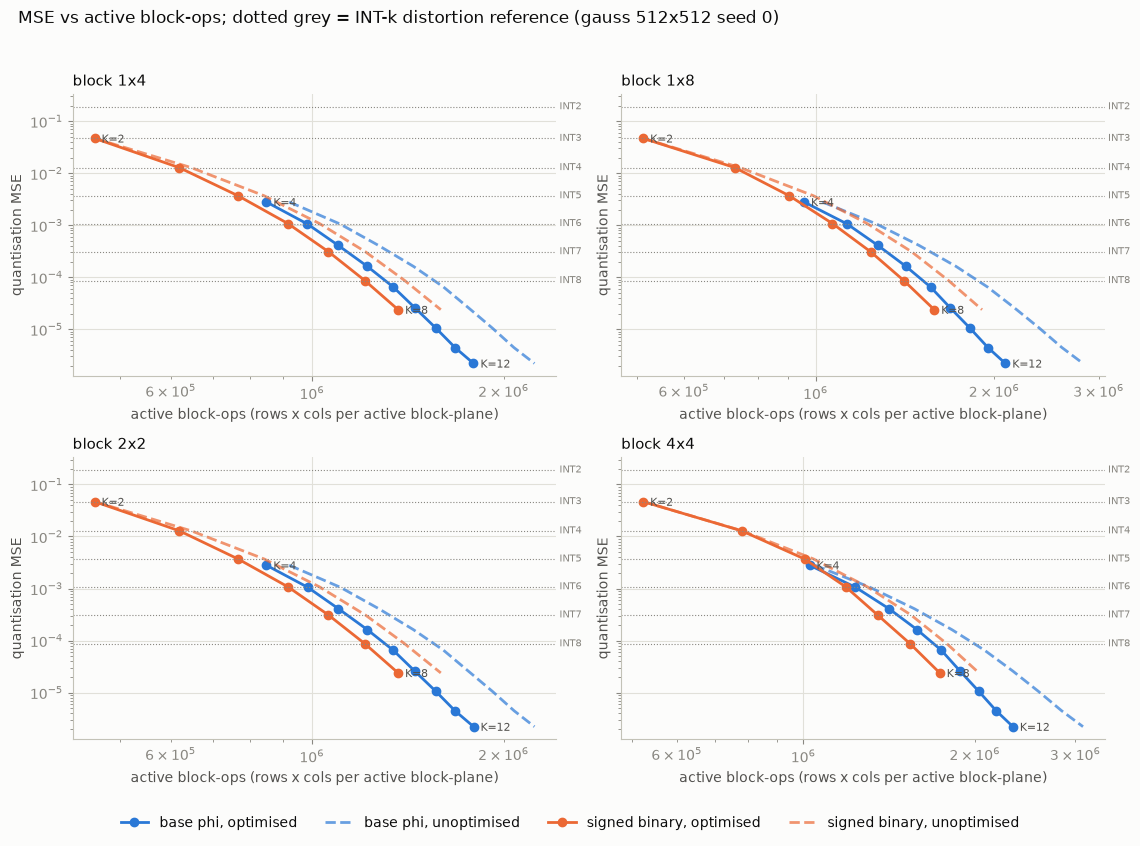

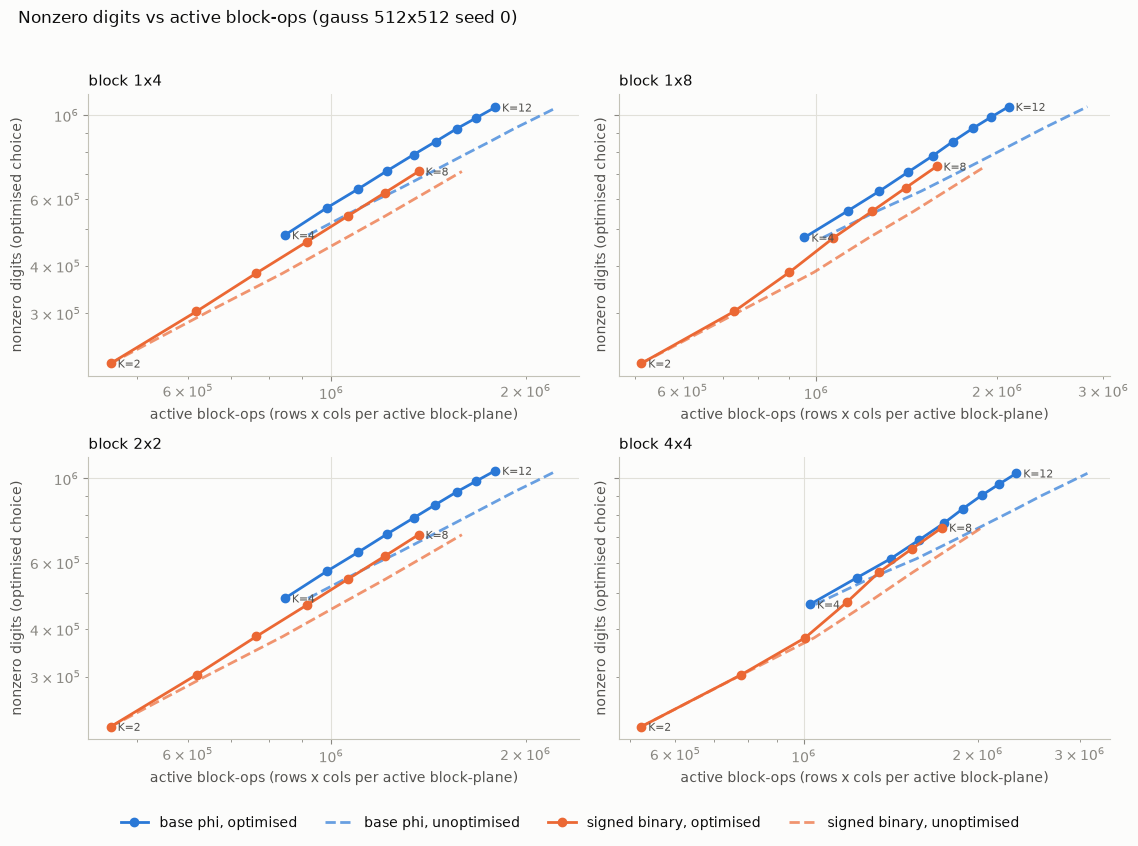

In [6]:
ref_blocks = [d for d in block_rows if (d['dist'], d['N'], d['seed']) == REF_MATRIX]
ref_mse = [d for d in mse_rows if (d['dist'], d['N'], d['seed']) == REF_MATRIX]
int_ref = sorted((d['K'], d['mse']) for d in ref_mse if d['base'] == 'int')
ref_title = f'{REF_MATRIX[0]} {REF_MATRIX[1]}x{REF_MATRIX[1]} seed {REF_MATRIX[2]}'

def series(base: str, shape: str, key: str):
    rows = sorted((d for d in ref_blocks if d['base'] == base and d['shape'] == shape), key=lambda d: d['K'])
    return np.array([d[key] for d in rows], dtype=float), np.array([d['K'] for d in rows])

def curve_plot(ykey: str, ylabel: str, fname: str, title: str, int_lines: bool):
    fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.5), sharey=True)
    for ax, (r, c) in zip(axes.ravel(), BLOCK_SHAPES):
        shape = f'{r}x{c}'
        for base in ('phi', 'bin'):
            y, Ks = series(base, shape, ykey)
            x_opt, _ = series(base, shape, 'ops_opt')
            x_un, _ = series(base, shape, 'ops_unopt')
            ax.plot(x_opt, y, '-', marker='o', color=COLORS[base], label=f'{LABEL[base]}, optimised')
            ax.plot(x_un, y, '--', color=COLORS[base], alpha=0.7, label=f'{LABEL[base]}, unoptimised')
            for j in (0, len(Ks) - 1):
                ax.annotate(f'K={Ks[j]}', (x_opt[j], y[j]), textcoords='offset points', xytext=(5, -3), fontsize=8, color='#52514e')
        if int_lines:
            for kb, m in int_ref:
                ax.axhline(m, color=C_INT, linewidth=0.8, linestyle=':')
                ax.text(1.0, m, f' INT{kb}', transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=7, color=C_INT)
        ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_title(f'block {shape}', loc='left', fontsize=11)
        ax.set_xlabel('active block-ops (rows x cols per active block-plane)')
        ax.set_ylabel(ylabel)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=4, bbox_to_anchor=(0.5, 0.0))
    fig.suptitle(f'{title} ({ref_title})', x=0.02, ha='left', fontsize=12)
    fig.tight_layout(rect=[0, 0.05, 1, 0.96])
    fig.savefig(FIGS / fname, bbox_inches='tight')
    return fig

curve_plot('mse', 'quantisation MSE', 'q1_fig1_mse_vs_active_ops.png',
           'MSE vs active block-ops; dotted grey = INT-k distortion reference', True)
plt.show()
curve_plot('nnz_opt', 'nonzero digits (optimised choice)', 'q1_fig2_nnz_vs_active_ops.png',
           'Nonzero digits vs active block-ops', False)
plt.show()


matched pair on gauss 512x512 seed 0: binary K=6 (mse 3.105e-04) vs phi K=6 (mse 4.089e-04)


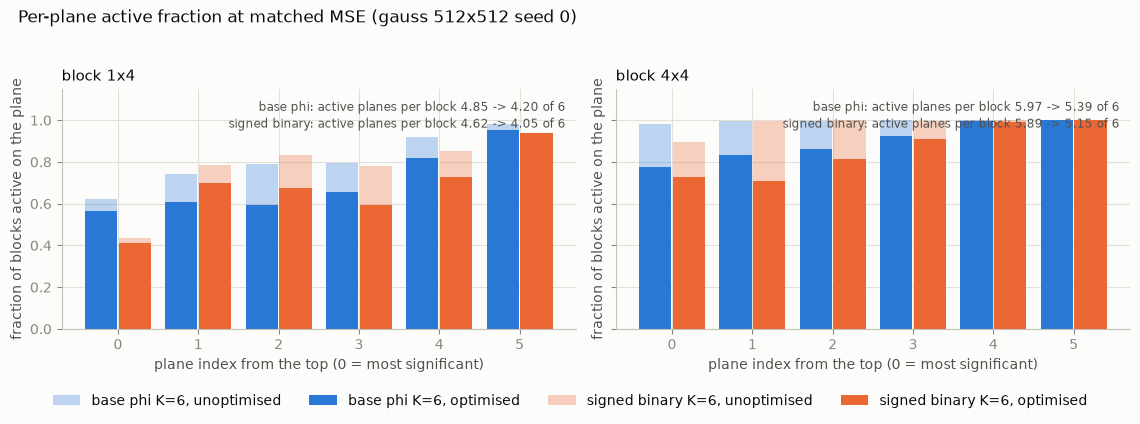

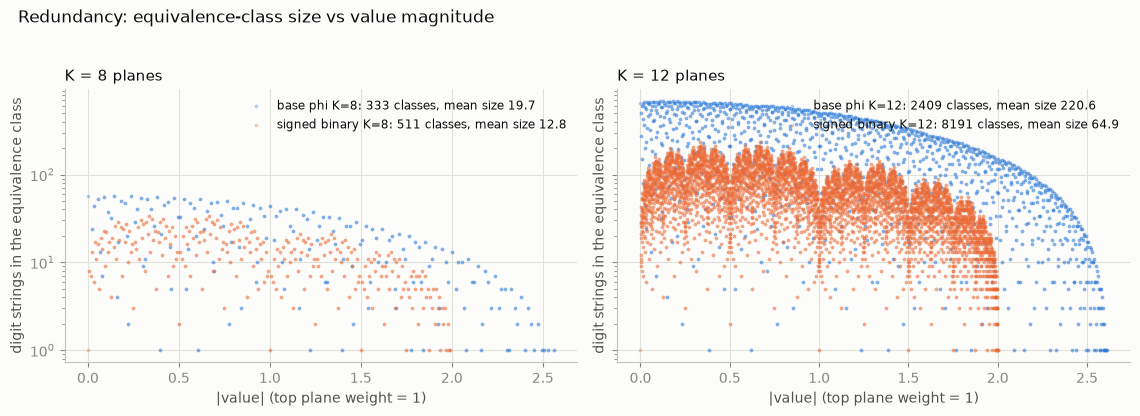

In [7]:
# figure 3: per-plane active fraction for one matched-MSE pair
mse_bin_ref = next(d['mse'] for d in ref_mse if d['base'] == 'bin' and d['K'] == REF_BIN_K)
phi_mse_ref = {d['K']: d['mse'] for d in ref_mse if d['base'] == 'phi'}
K_PHI_MATCH = min(phi_mse_ref, key=lambda k: abs(math.log(phi_mse_ref[k]) - math.log(mse_bin_ref)))
print(f'matched pair on {ref_title}: binary K={REF_BIN_K} (mse {mse_bin_ref:.3e}) vs phi K={K_PHI_MATCH} (mse {phi_mse_ref[K_PHI_MATCH]:.3e})')

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for ax, (r, c) in zip(axes, DECISION_SHAPES):
    shape = f'{r}x{c}'
    for i, (base, K) in enumerate((('phi', K_PHI_MATCH), ('bin', REF_BIN_K))):
        fr = sorted((d for d in plane_rows if (d['dist'], d['N'], d['seed']) == REF_MATRIX
                     and d['base'] == base and d['K'] == K and d['shape'] == shape), key=lambda d: d['plane_from_top'])
        x = np.array([d['plane_from_top'] for d in fr]) + (i - 0.5) * 0.42
        ax.bar(x, [d['frac_unopt'] for d in fr], width=0.4, color=COLORS[base], alpha=0.3, label=f'{LABEL[base]} K={K}, unoptimised')
        ax.bar(x, [d['frac_opt'] for d in fr], width=0.4, color=COLORS[base], label=f'{LABEL[base]} K={K}, optimised')
        tot_opt = sum(d['frac_opt'] for d in fr); tot_un = sum(d['frac_unopt'] for d in fr)
        ax.text(0.98, 0.95 - 0.07 * i, f'{LABEL[base]}: active planes per block {tot_un:.2f} -> {tot_opt:.2f} of {K}',
                transform=ax.transAxes, ha='right', va='top', fontsize=8.5, color='#52514e')
    ax.set_title(f'block {shape}', loc='left', fontsize=11)
    ax.set_xlabel('plane index from the top (0 = most significant)')
    ax.set_ylabel('fraction of blocks active on the plane')
    ax.set_ylim(0, 1.15)
    ax.set_xticks(range(max(K_PHI_MATCH, REF_BIN_K)))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, bbox_to_anchor=(0.5, 0.0))
fig.suptitle(f'Per-plane active fraction at matched MSE ({ref_title})', x=0.02, ha='left', fontsize=12)
fig.tight_layout(rect=[0, 0.08, 1, 0.95])
fig.savefig(FIGS / 'q1_fig3_plane_fraction.png', bbox_inches='tight')
plt.show()

# figure 4: class size vs value magnitude
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for ax, K in zip(axes, (8, 12)):
    for base in ('phi', 'bin'):
        tab = tables[(base, K)]
        ax.scatter(np.abs(tab.values), tab.sizes, s=7, alpha=0.35, color=COLORS[base], linewidths=0,
                   label=f'{LABEL[base]} K={K}: {tab.values.size} classes, mean size {tab.sizes.mean():.1f}')
    ax.set_yscale('log')
    ax.set_title(f'K = {K} planes', loc='left', fontsize=11)
    ax.set_xlabel('|value| (top plane weight = 1)')
    ax.set_ylabel('digit strings in the equivalence class')
    ax.legend(loc='upper right', fontsize=8.5)
fig.suptitle('Redundancy: equivalence-class size vs value magnitude', x=0.02, ha='left', fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(FIGS / 'q1_fig4_class_size.png', bbox_inches='tight')
plt.show()


## 6. Decision

At each binary K the phi curve (K = 4..12) is interpolated in log-log (MSE, active block-ops) space to the
binary MSE. `ratio = active_block_ops(phi) / active_block_ops(binary)` at equal MSE. Phi needs `1/log2(phi) = 1.44x`
the planes of binary for the same range, so its per-plane block density must be below `0.69x` binary's to tie;
`density_ratio` reports that directly. Rows outside the phi MSE range are not extrapolated (binary K = 2 usually
sits above phi K = 4's MSE). Verdict rule: **GO** if, for block shape 1x4 or 4x4, every in-range
(binary K, size, seed) on Gaussian weights has `ratio < 0.9`; otherwise **NO-GO**.


In [8]:
def select(rows, **kw):
    return [d for d in rows if all(d[k] == v for k, v in kw.items())]

decision_rows = []
for dist in DISTS:
    for N in SIZES:
        for seed in SEEDS:
            for (r, c) in BLOCK_SHAPES:
                shape = f'{r}x{c}'
                phi = sorted(select(block_rows, dist=dist, N=N, seed=seed, base='phi', shape=shape), key=lambda d: d['mse'])
                lm = np.log([d['mse'] for d in phi])
                lo_opt = np.log([d['ops_opt'] for d in phi]); lo_un = np.log([d['ops_unopt'] for d in phi])
                lnnz = np.log([d['nnz_opt'] for d in phi]); Kp = np.array([d['K'] for d in phi], float)
                for d in sorted(select(block_rows, dist=dist, N=N, seed=seed, base='bin', shape=shape), key=lambda d: d['K']):
                    x = math.log(d['mse'])
                    in_range = bool(lm[0] <= x <= lm[-1])
                    row = dict(dist=dist, N=N, seed=seed, shape=shape, bin_K=d['K'], mse_bin=d['mse'],
                               ops_bin_opt=d['ops_opt'], ops_bin_unopt=d['ops_unopt'], in_range=in_range,
                               K_phi_equiv=float('nan'), ops_phi_opt=float('nan'), ratio_opt=float('nan'),
                               ratio_unopt=float('nan'), density_ratio=float('nan'), nnz_ratio=float('nan'))
                    if in_range:
                        K_eq = float(np.interp(x, lm, Kp))
                        ops_phi = math.exp(float(np.interp(x, lm, lo_opt)))
                        row.update(K_phi_equiv=K_eq, ops_phi_opt=ops_phi, ratio_opt=ops_phi / d['ops_opt'],
                                   ratio_unopt=math.exp(float(np.interp(x, lm, lo_un))) / d['ops_unopt'],
                                   density_ratio=ops_phi / d['ops_opt'] * d['K'] / K_eq,
                                   nnz_ratio=math.exp(float(np.interp(x, lm, lnnz))) / d['nnz_opt'])
                    decision_rows.append(row)
write_csv(RES / 'q1_decision.csv', decision_rows)

def fmt(v: float) -> str:
    return '-' if (isinstance(v, float) and math.isnan(v)) else f'{v:.3f}'

lines = ['## Decision (computed from results/q1_decision.csv)', '',
         f'Ratio = active block-ops(phi) / active block-ops(binary) at the binary MSE (phi curve interpolated in log-log). '
         f'Per-plane density ratio must be below 0.69 for phi to tie (phi uses 1.44x the planes). '
         f'Cells: min / median / max over sizes {SIZES} and seeds {SEEDS}; n = in-range configurations. '
         f'Unoptimised ratio is the same comparison without block coordination.', '']
for dist in DISTS:
    lines += [f'### {dist} weights', '']
    for (r, c) in BLOCK_SHAPES:
        shape = f'{r}x{c}'
        lines += [f'**block {shape}**', '',
                  '| binary K | MSE (256, seed 0) | ratio min | ratio median | ratio max | density ratio median | unoptimised ratio median | nonzero-digit ratio median | n |',
                  '|---|---|---|---|---|---|---|---|---|']
        for Kb in K_RANGE['bin']:
            rs = [d for d in decision_rows if d['dist'] == dist and d['shape'] == shape and d['bin_K'] == Kb]
            ok = [d for d in rs if d['in_range']]
            mse0 = next((d['mse_bin'] for d in rs if d['N'] == 256 and d['seed'] == 0), float('nan'))
            if not ok:
                lines.append(f'| {Kb} | {mse0:.2e} | - | - | - | - | - | - | 0 (outside phi MSE range) |')
                continue
            ra = np.array([d['ratio_opt'] for d in ok]); dr = np.median([d['density_ratio'] for d in ok])
            ru = np.median([d['ratio_unopt'] for d in ok]); rn = np.median([d['nnz_ratio'] for d in ok])
            lines.append(f'| {Kb} | {mse0:.2e} | {ra.min():.3f} | {np.median(ra):.3f} | {ra.max():.3f} | {dr:.3f} | {ru:.3f} | {rn:.3f} | {len(ok)} |')
        lines.append('')

verdicts = {}
lines += ['### Verdict', '']
for (r, c) in DECISION_SHAPES:
    shape = f'{r}x{c}'
    ok = [d for d in decision_rows if d['dist'] == 'gauss' and d['shape'] == shape and d['in_range']]
    if not ok:
        verdicts[shape] = False
        lines.append(f'- block {shape}: no in-range matched-MSE points -> fails')
        continue
    worst = max(d['ratio_opt'] for d in ok); best = min(d['ratio_opt'] for d in ok)
    per_seed = {seed: max([d['ratio_opt'] for d in ok if d['seed'] == seed] or [float('nan')]) for seed in SEEDS}
    passed = worst < GO_THRESHOLD
    verdicts[shape] = passed
    lines.append(f'- block {shape} (Gaussian, all in-range binary K, both sizes): worst ratio {worst:.3f}, best {best:.3f}; '
                 f'worst per seed ' + ', '.join(f'seed {s}: {v:.3f}' for s, v in per_seed.items()) +
                 f' -> {"passes" if passed else "fails"} the < {GO_THRESHOLD} test')
GO = any(verdicts.values())
lines += ['', f'# {"GO" if GO else "NO-GO"}', '',
          (f'Phi beats signed binary by more than 10% in active block-ops at every matched MSE for '
           f'{", ".join(s for s, v in verdicts.items() if v)}.') if GO else
          (f'At matched MSE, phi does not get its active block-ops below {GO_THRESHOLD}x binary consistently for 1x4 or 4x4 '
           f'even though both get the same block optimiser; see the density ratios above (needs < 0.69 to tie).')]
DECISION_MD = '\n'.join(lines)
(RES / 'q1_decision.md').write_text(DECISION_MD + '\n')
try:
    _ip = get_ipython()   # noqa: F821  (defined only inside a Jupyter kernel)
except NameError:
    _ip = None
if _ip is not None:
    from IPython.display import Markdown, display
    display(Markdown(DECISION_MD))
else:
    print(DECISION_MD)


## Decision (computed from results/q1_decision.csv)

Ratio = active block-ops(phi) / active block-ops(binary) at the binary MSE (phi curve interpolated in log-log). Per-plane density ratio must be below 0.69 for phi to tie (phi uses 1.44x the planes). Cells: min / median / max over sizes [256, 512] and seeds [0, 1, 2]; n = in-range configurations. Unoptimised ratio is the same comparison without block coordination.

### gauss weights

**block 1x4**

| binary K | MSE (256, seed 0) | ratio min | ratio median | ratio max | density ratio median | unoptimised ratio median | nonzero-digit ratio median | n |
|---|---|---|---|---|---|---|---|---|
| 2 | 4.77e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 3 | 1.31e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 4 | 3.83e-03 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 5 | 1.13e-03 | 1.066 | 1.070 | 1.074 | 1.075 | 1.074 | 1.223 | 6 |
| 6 | 3.29e-04 | 1.069 | 1.074 | 1.082 | 1.023 | 1.094 | 1.223 | 6 |
| 7 | 8.97e-05 | 1.068 | 1.074 | 1.077 | 0.979 | 1.109 | 1.220 | 6 |
| 8 | 2.41e-05 | 1.068 | 1.069 | 1.071 | 0.941 | 1.113 | 1.207 | 6 |

**block 1x8**

| binary K | MSE (256, seed 0) | ratio min | ratio median | ratio max | density ratio median | unoptimised ratio median | nonzero-digit ratio median | n |
|---|---|---|---|---|---|---|---|---|
| 2 | 4.77e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 3 | 1.31e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 4 | 3.83e-03 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 5 | 1.13e-03 | 1.051 | 1.055 | 1.057 | 1.060 | 1.034 | 1.176 | 6 |
| 6 | 3.29e-04 | 1.063 | 1.067 | 1.075 | 1.016 | 1.081 | 1.176 | 6 |
| 7 | 8.97e-05 | 1.069 | 1.076 | 1.078 | 0.980 | 1.120 | 1.178 | 6 |
| 8 | 2.41e-05 | 1.070 | 1.071 | 1.073 | 0.943 | 1.143 | 1.171 | 6 |

**block 2x2**

| binary K | MSE (256, seed 0) | ratio min | ratio median | ratio max | density ratio median | unoptimised ratio median | nonzero-digit ratio median | n |
|---|---|---|---|---|---|---|---|---|
| 2 | 4.77e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 3 | 1.31e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 4 | 3.83e-03 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 5 | 1.13e-03 | 1.065 | 1.071 | 1.077 | 1.075 | 1.074 | 1.223 | 6 |
| 6 | 3.29e-04 | 1.070 | 1.074 | 1.083 | 1.023 | 1.095 | 1.224 | 6 |
| 7 | 8.97e-05 | 1.070 | 1.075 | 1.076 | 0.979 | 1.109 | 1.219 | 6 |
| 8 | 2.41e-05 | 1.066 | 1.069 | 1.069 | 0.941 | 1.113 | 1.208 | 6 |

**block 4x4**

| binary K | MSE (256, seed 0) | ratio min | ratio median | ratio max | density ratio median | unoptimised ratio median | nonzero-digit ratio median | n |
|---|---|---|---|---|---|---|---|---|
| 2 | 4.77e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 3 | 1.31e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 4 | 3.83e-03 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 5 | 1.13e-03 | 1.035 | 1.037 | 1.043 | 1.041 | 1.008 | 1.152 | 6 |
| 6 | 3.29e-04 | 1.083 | 1.088 | 1.092 | 1.035 | 1.064 | 1.130 | 6 |
| 7 | 8.97e-05 | 1.092 | 1.099 | 1.100 | 1.001 | 1.118 | 1.130 | 6 |
| 8 | 2.41e-05 | 1.091 | 1.093 | 1.099 | 0.962 | 1.158 | 1.128 | 6 |

### laplace weights

**block 1x4**

| binary K | MSE (256, seed 0) | ratio min | ratio median | ratio max | density ratio median | unoptimised ratio median | nonzero-digit ratio median | n |
|---|---|---|---|---|---|---|---|---|
| 2 | 8.69e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 3 | 2.99e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 4 | 1.03e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 5 | 3.41e-03 | 1.097 | 1.103 | 1.122 | 1.102 | 1.109 | 1.267 | 6 |
| 6 | 1.06e-03 | 1.090 | 1.106 | 1.114 | 1.049 | 1.110 | 1.251 | 6 |
| 7 | 2.99e-04 | 1.091 | 1.098 | 1.110 | 0.998 | 1.113 | 1.240 | 6 |
| 8 | 7.81e-05 | 1.083 | 1.085 | 1.088 | 0.955 | 1.110 | 1.224 | 6 |

**block 1x8**

| binary K | MSE (256, seed 0) | ratio min | ratio median | ratio max | density ratio median | unoptimised ratio median | nonzero-digit ratio median | n |
|---|---|---|---|---|---|---|---|---|
| 2 | 8.69e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 3 | 2.99e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 4 | 1.03e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 5 | 3.41e-03 | 1.064 | 1.072 | 1.090 | 1.070 | 1.079 | 1.242 | 6 |
| 6 | 1.06e-03 | 1.078 | 1.093 | 1.100 | 1.036 | 1.099 | 1.220 | 6 |
| 7 | 2.99e-04 | 1.087 | 1.094 | 1.108 | 0.994 | 1.118 | 1.205 | 6 |
| 8 | 7.81e-05 | 1.084 | 1.086 | 1.091 | 0.955 | 1.133 | 1.191 | 6 |

**block 2x2**

| binary K | MSE (256, seed 0) | ratio min | ratio median | ratio max | density ratio median | unoptimised ratio median | nonzero-digit ratio median | n |
|---|---|---|---|---|---|---|---|---|
| 2 | 8.69e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 3 | 2.99e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 4 | 1.03e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 5 | 3.41e-03 | 1.096 | 1.104 | 1.122 | 1.103 | 1.108 | 1.266 | 6 |
| 6 | 1.06e-03 | 1.090 | 1.105 | 1.113 | 1.048 | 1.110 | 1.252 | 6 |
| 7 | 2.99e-04 | 1.090 | 1.098 | 1.110 | 0.998 | 1.111 | 1.240 | 6 |
| 8 | 7.81e-05 | 1.083 | 1.085 | 1.088 | 0.955 | 1.111 | 1.224 | 6 |

**block 4x4**

| binary K | MSE (256, seed 0) | ratio min | ratio median | ratio max | density ratio median | unoptimised ratio median | nonzero-digit ratio median | n |
|---|---|---|---|---|---|---|---|---|
| 2 | 8.69e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 3 | 2.99e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 4 | 1.03e-02 | - | - | - | - | - | - | 0 (outside phi MSE range) |
| 5 | 3.41e-03 | 1.058 | 1.064 | 1.077 | 1.062 | 1.064 | 1.219 | 6 |
| 6 | 1.06e-03 | 1.084 | 1.099 | 1.106 | 1.043 | 1.109 | 1.194 | 6 |
| 7 | 2.99e-04 | 1.108 | 1.115 | 1.124 | 1.013 | 1.142 | 1.167 | 6 |
| 8 | 7.81e-05 | 1.108 | 1.111 | 1.113 | 0.977 | 1.168 | 1.149 | 6 |

### Verdict

- block 1x4 (Gaussian, all in-range binary K, both sizes): worst ratio 1.082, best 1.066; worst per seed seed 0: 1.076, seed 1: 1.082, seed 2: 1.075 -> fails the < 0.9 test
- block 4x4 (Gaussian, all in-range binary K, both sizes): worst ratio 1.100, best 1.035; worst per seed seed 0: 1.100, seed 1: 1.099, seed 2: 1.099 -> fails the < 0.9 test

# NO-GO

At matched MSE, phi does not get its active block-ops below 0.9x binary consistently for 1x4 or 4x4 even though both get the same block optimiser; see the density ratios above (needs < 0.69 to tie).

## 7. Save the optimised digit planes for the kernel notebook

`results/q1_planes.npz` holds, for the matched pair on the reference matrix, the int8 digit planes (`K x N x N`,
plane index `k` has weight `b^(k-(K-1))`, so index `K-1` is the top plane), the block activity masks per block shape
(`K x N/r x N/c` bool), the canonical (unoptimised) planes, the scale, and the original weights.


In [9]:
N_ref = REF_MATRIX[1]
out = dict(W=W_ref.astype(np.float32), dist=REF_MATRIX[0], N=N_ref, seed=REF_MATRIX[2], phi=PHI,
           bin_K=REF_BIN_K, phi_K=K_PHI_MATCH, block_shapes=np.array([f'{r}x{c}' for r, c in BLOCK_SHAPES + DIAG_SHAPES]))
for base, K in (('phi', K_PHI_MATCH), ('bin', REF_BIN_K)):
    b = PHI if base == 'phi' else 2.0
    weights = b ** (np.arange(K) - (K - 1))
    for (r, c) in BLOCK_SHAPES + DIAG_SHAPES:
        shape = f'{r}x{c}'
        art = kept[(base, K, shape)]
        planes = np.stack([from_blocks(art['digits'][:, :, k], N_ref, r, c) for k in range(K)]).astype(np.int8)
        canon_planes = np.stack([from_blocks(art['canon_digits'][:, :, k], N_ref, r, c) for k in range(K)]).astype(np.int8)
        recon = art['s'] * np.tensordot(weights, planes.astype(np.float64), axes=(0, 0))
        recon_c = art['s'] * np.tensordot(weights, canon_planes.astype(np.float64), axes=(0, 0))
        assert np.allclose(recon, recon_c, atol=1e-9) and abs(np.mean((recon - W_ref) ** 2) - art['mse']) < 1e-9
        bits = ((art['T'][:, None] >> np.arange(K)) & 1).astype(bool)
        block_mask = bits.reshape(N_ref // r, N_ref // c, K).transpose(2, 0, 1)
        assert np.all(block_mask.sum() * r * c == select(block_rows, dist=REF_MATRIX[0], N=N_ref, seed=REF_MATRIX[2], base=base, K=K, shape=shape)[0]['ops_opt'])
        out[f'{base}_planes_opt_{shape}'] = planes
        out[f'{base}_block_mask_{shape}'] = block_mask
        if shape == '4x4':
            out[f'{base}_planes_canon'] = canon_planes
            out[f'{base}_plane_weights'] = weights
            out[f'{base}_scale'] = art['s']
            out[f'{base}_mse'] = art['mse']
np.savez_compressed(RES / 'q1_planes.npz', **out)
sz = (RES / 'q1_planes.npz').stat().st_size / 1e6
print(f'[{elapsed()}] saved results/q1_planes.npz ({sz:.1f} MB) with keys: {sorted(out.keys())}')
print(f'total runtime {elapsed()}')


[  187.8s] saved results/q1_planes.npz (5.3 MB) with keys: ['N', 'W', 'bin_K', 'bin_block_mask_1x4', 'bin_block_mask_1x8', 'bin_block_mask_2x2', 'bin_block_mask_4x4', 'bin_block_mask_8x8', 'bin_mse', 'bin_plane_weights', 'bin_planes_canon', 'bin_planes_opt_1x4', 'bin_planes_opt_1x8', 'bin_planes_opt_2x2', 'bin_planes_opt_4x4', 'bin_planes_opt_8x8', 'bin_scale', 'block_shapes', 'dist', 'phi', 'phi_K', 'phi_block_mask_1x4', 'phi_block_mask_1x8', 'phi_block_mask_2x2', 'phi_block_mask_4x4', 'phi_block_mask_8x8', 'phi_mse', 'phi_plane_weights', 'phi_planes_canon', 'phi_planes_opt_1x4', 'phi_planes_opt_1x8', 'phi_planes_opt_2x2', 'phi_planes_opt_4x4', 'phi_planes_opt_8x8', 'phi_scale', 'seed']
total runtime   187.8s
